In [1]:
import pandas as pd
import numpy as np

In [1]:
! pip install rdkit pandas

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from rdkit import Chem

In [3]:
Mol_df = pd.read_csv('ci034243x_si_001.txt')
Mol_df.head(2)

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES
0,"1,1,1,2-Tetrachloroethane",-2.18,-2.794,ClCC(Cl)(Cl)Cl
1,"1,1,1-Trichloroethane",-2.00,-2.232,CC(Cl)(Cl)Cl


In [4]:
Mol_df.SMILES   ##  or  Mol_df['SMILES']

0                                    ClCC(Cl)(Cl)Cl
1                                      CC(Cl)(Cl)Cl
2                                    ClC(Cl)C(Cl)Cl
3                                        ClCC(Cl)Cl
4                               FC(F)(Cl)C(F)(Cl)Cl
                           ...                     
1139                   CNC(=O)C(C)SCCSP(=O)(OC)(OC)
1140          CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C
1141         CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O 
1142    Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O
1143                         CNC(=O)Oc1cc(C)cc(C)c1
Name: SMILES, Length: 1144, dtype: str

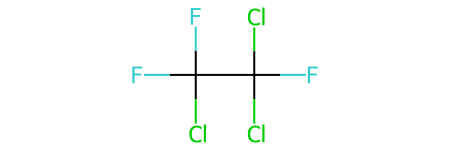

In [5]:
## parsing the molecules

m = Chem.MolFromSmiles(Mol_df['SMILES'].iloc[4])
m

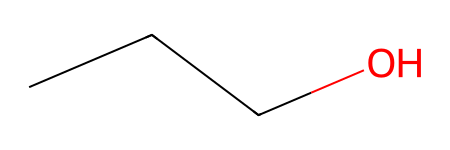

In [6]:
m = Chem.MolFromSmiles(Mol_df['SMILES'].iloc[114])
m

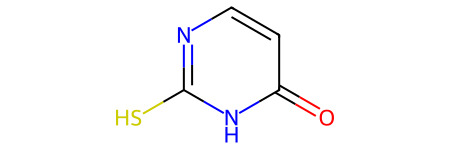

In [7]:
m = Chem.MolFromSmiles(Mol_df['SMILES'].iloc[1100])
m

In [ ]:
## downloading the MOL files from web

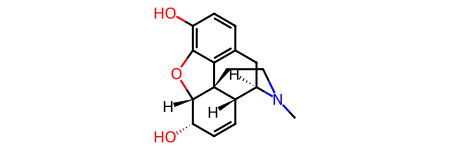

In [8]:
import requests

morphine_url = 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/morphine/SDF?record_type=2d'
response = requests.get(morphine_url)
response.raise_for_status()

morphine_mol = response.text
morphine_strc = Chem.MolFromMolBlock(morphine_mol)
morphine_strc

In [9]:
from rdkit.Chem import Descriptors

Descriptors.MolWt(morphine_strc)

285.34299999999996

In [10]:
Descriptors.MolLogP(morphine_strc)

1.1980999999999997

In [11]:
Descriptors.NumRotatableBonds(morphine_strc)

0

In [12]:
morphine_strc.GetNumAtoms()   ### non hydrogen atoms only

21

In [13]:

[atom.GetSymbol() for atom in morphine_strc.GetAtoms() if not atom.IsInRing()]

['O', 'O', 'C']

In [14]:
[atom.GetSymbol() for atom in morphine_strc.GetAtoms()]   ###  now it gives all the atoms

['O',
 'O',
 'O',
 'N',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C']

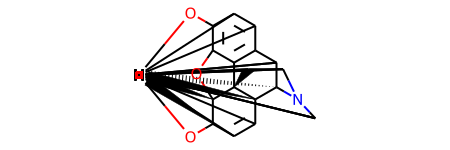

In [15]:
##  adding the missing Hydrogens

morphine_hydrogens = Chem.AddHs(morphine_strc)
morphine_hydrogens                  ### all are attacxhed at a same point

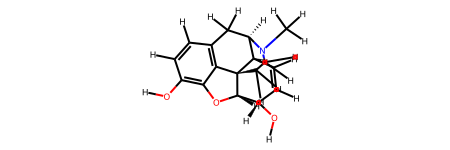

In [16]:
##  for more appropriate structure

from rdkit.Chem import AllChem

AllChem.Compute2DCoords(morphine_hydrogens)
morphine_hydrogens

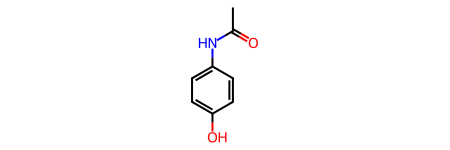

In [19]:
tylenol_url = 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/tylenol/SDF?record_type=2d'
response = requests.get(tylenol_url)
response.raise_for_status()

tylenol_mol = response.text
tylenol_strc = Chem.MolFromMolBlock(tylenol_mol)
tylenol_strc

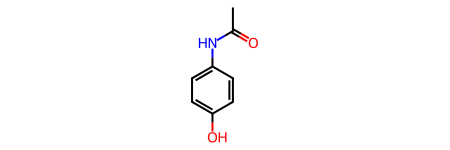

In [20]:
## by CID

tylenol_url_CID = 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/1983/SDF?record_type=2d'
response = requests.get(tylenol_url_CID)
response.raise_for_status()

tylenol_CID = response.text
tylenol_strc = Chem.MolFromMolBlock(tylenol_CID)
tylenol_strc

In [21]:
Mol_df.head(2)

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES
0,"1,1,1,2-Tetrachloroethane",-2.18,-2.794,ClCC(Cl)(Cl)Cl
1,"1,1,1-Trichloroethane",-2.00,-2.232,CC(Cl)(Cl)Cl


#### Fetching the SMILES Column

In [22]:

Mol_df.SMILES

0                                    ClCC(Cl)(Cl)Cl
1                                      CC(Cl)(Cl)Cl
2                                    ClC(Cl)C(Cl)Cl
3                                        ClCC(Cl)Cl
4                               FC(F)(Cl)C(F)(Cl)Cl
                           ...                     
1139                   CNC(=O)C(C)SCCSP(=O)(OC)(OC)
1140          CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C
1141         CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O 
1142    Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O
1143                         CNC(=O)Oc1cc(C)cc(C)c1
Name: SMILES, Length: 1144, dtype: str

In [23]:
Mol_df.SMILES[1139]

'CNC(=O)C(C)SCCSP(=O)(OC)(OC)'

#### Converting the SMILES string into RDkit object

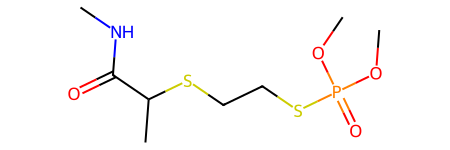

In [24]:
Chem.MolFromSmiles(Mol_df.SMILES[1139])

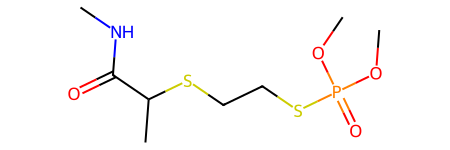

In [25]:
Chem.MolFromSmiles('CNC(=O)C(C)SCCSP(=O)(OC)(OC)')

#### Working with RDkit object

In [26]:
m2 = Chem.MolFromSmiles('CNC(=O)C(C)SCCSP(=O)(OC)(OC)')

In [27]:
m2.GetNumAtoms()

16

#### Calcuating molecular discriptors

In [28]:
from rdkit import Chem

In [29]:
mol_list = []

for element in Mol_df.SMILES:
    mol = Chem.MolFromSmiles(element)
    mol_list.append(mol)

In [30]:
len(mol_list)

1144

In [31]:
mol_list[:5]

####  Calculating molecular descriptors

In [39]:

from rdkit.Chem import Descriptors

def esol(SMILES):

    moldata= []
    for elem in SMILES:
        mol=Chem.MolFromSmiles(elem) 
        moldata.append(mol)


    baseData = np.arange(1,1)
    i = 0
    for mol in moldata:
        
        desc_MolLogP = Descriptors.MolLogP(mol)
        desc_MolWt = Descriptors.MolWt(mol)
        desc_NumRotatableBonds = Descriptors.NumRotatableBonds(mol)
        AP = sum(a.GetIsAromatic() for a in mol.GetAtoms()) / mol.GetNumHeavyAtoms()

        row = np.array([desc_MolLogP, desc_MolWt, desc_NumRotatableBonds, AP])
        
        if (i == 0):
            baseData = row
        else:
            baseData = np.vstack([baseData, row])
        i= i+1    
        
    columnNames = ["MolLogP","MolWt","NumRotatableBonds", "AP"]
    descriptors = pd.DataFrame(data = baseData, columns = columnNames)  

    return descriptors  

In [40]:

Data = esol(Mol_df.SMILES)
Data

,MolLogP,MolWt,NumRotatableBonds,AP
0,2.59540,167.850,0.0,0.000000
1,2.37650,133.405,0.0,0.000000
2,2.59380,167.850,1.0,0.000000
3,2.02890,133.405,1.0,0.000000
4,2.91890,187.375,1.0,0.000000
...,...,...,...,...
1139,1.98820,287.343,8.0,0.000000
1140,3.42130,286.114,2.0,0.333333
1141,3.60960,308.333,4.0,0.695652
1142,2.56214,354.815,3.0,0.521739


In [41]:
X = Data
X

,MolLogP,MolWt,NumRotatableBonds,AP
0,2.59540,167.850,0.0,0.000000
1,2.37650,133.405,0.0,0.000000
2,2.59380,167.850,1.0,0.000000
3,2.02890,133.405,1.0,0.000000
4,2.91890,187.375,1.0,0.000000
...,...,...,...,...
1139,1.98820,287.343,8.0,0.000000
1140,3.42130,286.114,2.0,0.333333
1141,3.60960,308.333,4.0,0.695652
1142,2.56214,354.815,3.0,0.521739


In [42]:
Y = Mol_df.iloc[:, 1]
Y

0      -2.180
1      -2.000
2      -1.740
3      -1.480
4      -3.040
        ...  
1139    1.144
1140   -4.925
1141   -3.893
1142   -3.790
1143   -2.581
Name: measured log(solubility:mol/L), Length: 1144, dtype: float64

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3)

In [45]:
lr = LinearRegression()

lr.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.76,-0.01,-0.01,-0.42]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['MolLogP','MolWt','NumRotatableBonds','AP']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.2695
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [49]:
Y_pred_train = lr.predict(X_train)

print('Coefficients:', lr.coef_)
print('Intercept:', lr.intercept_)
print('Mean squared error (MSE): %.2f'
      % mean_squared_error(Y_train, Y_pred_train))
print('Coefficient of determination (R^2): %.2f'
      % r2_score(Y_train, Y_pred_train))

Coefficients: [-0.76139703 -0.00631532 -0.00505088 -0.42165557]
Intercept: 0.26952056459635587
Mean squared error (MSE): 0.96
Coefficient of determination (R^2): 0.77


In [50]:
Y_pred_test = lr.predict(X_test)

In [51]:
print('Coefficients:', lr.coef_)
print('Intercept:', lr.intercept_)
print('Mean squared error (MSE): %.2f'
      % mean_squared_error(Y_test, Y_pred_test))
print('Coefficient of determination (R^2): %.2f'
      % r2_score(Y_test, Y_pred_test))

Coefficients: [-0.76139703 -0.00631532 -0.00505088 -0.42165557]
Intercept: 0.26952056459635587
Mean squared error (MSE): 1.13
Coefficient of determination (R^2): 0.76
